# Small Multiples (line)

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Repeats the same small chart, with the same axes and scale, once per series. Each series gets its own panel, so comparison is about shape rather than untangling colors.

## When to use

- Compare trends across many groups (5–30)
- Series overlap too much on a single chart
- Pattern shape matters more than precise cross-series values

## Avoid when

- Precise comparison of two series at the same time point is required (overlay them)
- Panels would need different y-scales and readers would compare heights across panels

## Alternatives

- Highlighted line chart
- Heatmap (time × group)

## Design tips

- Share both axes (sharex/sharey) so panels are comparable
- Show the other series faintly in each panel for context
- Order panels meaningfully (by latest value, by region), not alphabetically by default

## Example

Weekly sales index for 9 stores over one year.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(8)
weeks = np.arange(1, 53)
stores = [f"Store {c}" for c in "ABCDEFGHI"]
df = pd.DataFrame({s: 100 + rng.normal(0, 0.8) * weeks + 10 * np.sin(weeks / 8 + rng.uniform(0, 6))
                   + rng.normal(0, 3, 52).cumsum() / 2 for s in stores}, index=weeks)
df = df[df.iloc[-1].sort_values(ascending=False).index]
labels = dict(x="Week", y="Sales index", title="Weekly sales index by store (sorted by final value)")
df.iloc[:5, :5]

,Store B,Store E,Store H,Store I,Store C
1,95.728401,103.017515,91.558937,110.301981,105.071750
2,100.390182,99.002689,90.742727,112.063396,106.282881
3,102.544964,94.572154,92.941946,112.916020,108.154900
4,103.482445,95.128439,97.348648,112.654155,106.969395
5,104.814901,94.296294,98.819696,112.685955,108.728593


### Plot

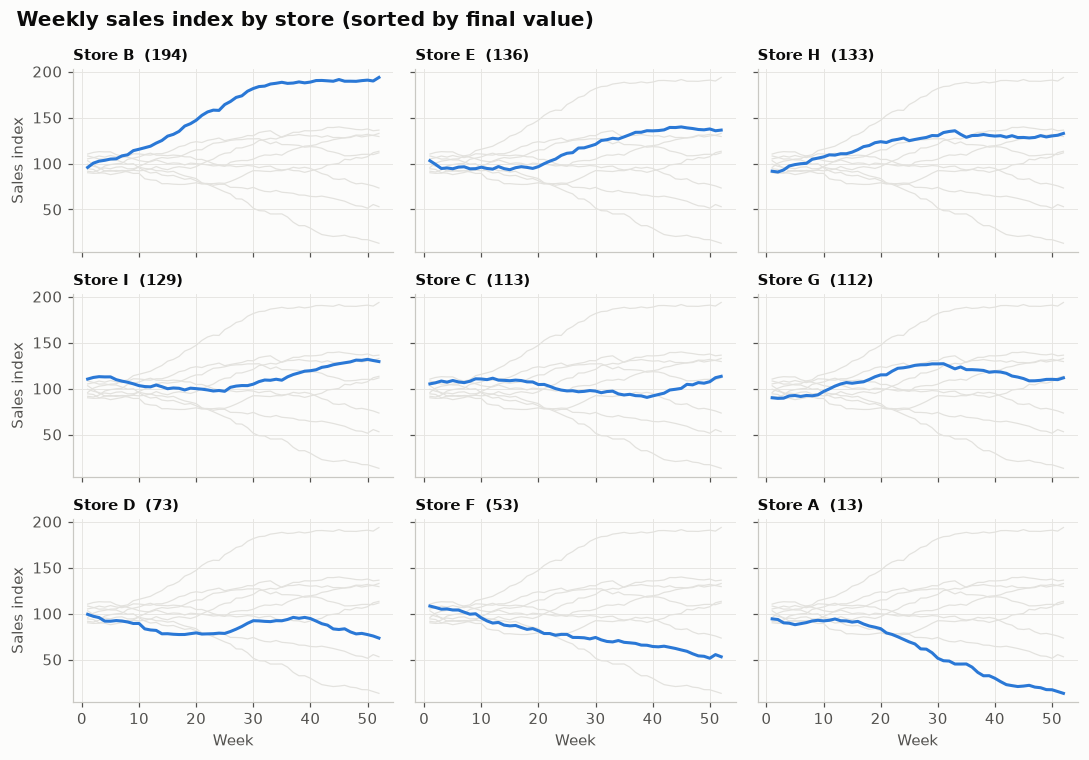

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(10, 7), sharex=True, sharey=True)
for ax, col in zip(axes.flat, df.columns):
    for other in df.columns:
        ax.plot(df.index, df[other], color="#e3e2de", linewidth=0.8)
    ax.plot(df.index, df[col], color=PALETTE[0], linewidth=2)
    ax.set_title(f"{col}  ({df[col].iloc[-1]:.0f})", fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel(labels["x"])
for ax in axes[:, 0]:
    ax.set_ylabel(labels["y"])
fig.suptitle(labels["title"], x=0.02, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

## Try it with real data

**Source:** plotly.express.data.gapminder() — Gapminder life expectancy, GDP and population 1952–2007, bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px
countries = ["Japan", "Chile", "China", "Brazil", "India", "Iraq", "Rwanda", "South Africa", "Zimbabwe"]
gm = px.data.gapminder().query("country in @countries")
df = gm.pivot(index="year", columns="country", values="lifeExp").rename_axis(columns=None)
df = df[df.iloc[-1].sort_values(ascending=False).index]
labels = dict(x="Year", y="Life exp. (yrs)", title="Life expectancy 1952–2007 (sorted by 2007 value)")
df.iloc[:5, :5]

,Japan,Chile,China,Brazil,India
year,,,,,
1952,63.03,54.745,44.00000,50.917,37.373
1957,65.50,56.074,50.54896,53.285,40.249
1962,68.73,57.924,44.50136,55.665,43.605
1967,71.43,60.523,58.38112,57.632,47.193
1972,73.42,63.441,63.11888,59.504,50.651


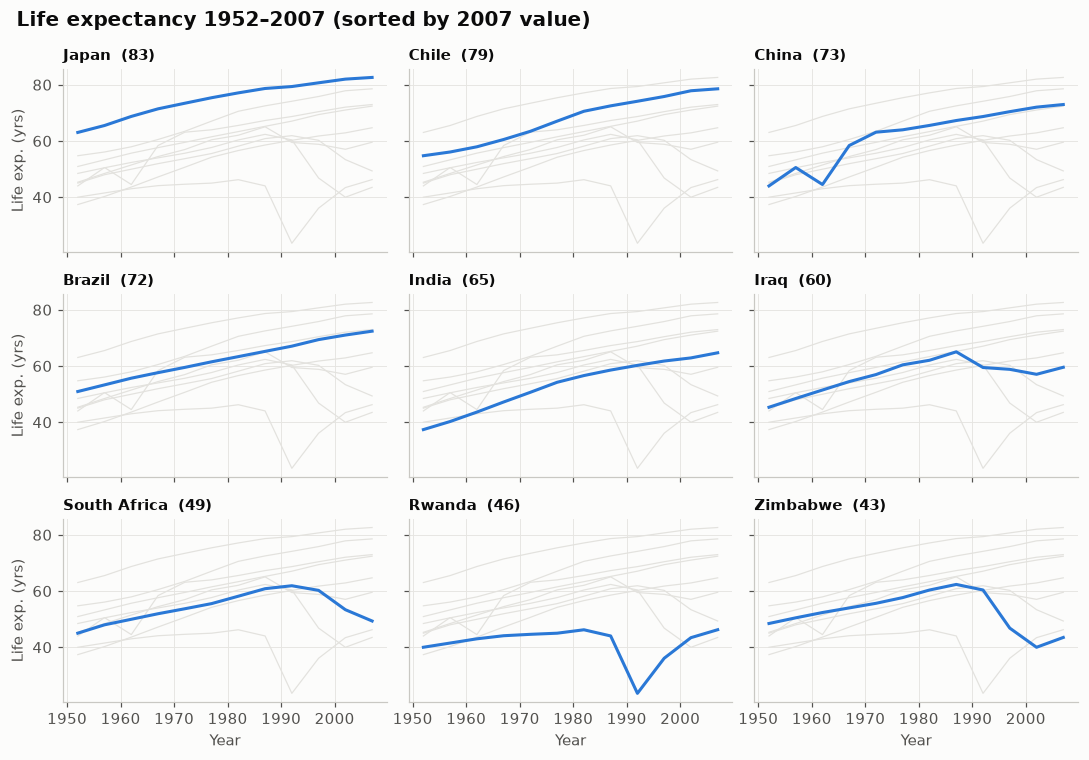

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(10, 7), sharex=True, sharey=True)
for ax, col in zip(axes.flat, df.columns):
    for other in df.columns:
        ax.plot(df.index, df[other], color="#e3e2de", linewidth=0.8)
    ax.plot(df.index, df[col], color=PALETTE[0], linewidth=2)
    ax.set_title(f"{col}  ({df[col].iloc[-1]:.0f})", fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel(labels["x"])
for ax in axes[:, 0]:
    ax.set_ylabel(labels["y"])
fig.suptitle(labels["title"], x=0.02, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

---
Standalone script: [`small_multiples_line.py`](small_multiples_line.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)